# Convolutional neural networks

In this notebook, we'll put together our convolutional layers to implement a 3-layer CNN.  Then, we'll ask you to implement a CNN that can achieve > 65% validation error on CIFAR-10.

CS231n has built a solid API for building these modular frameworks and training them, and we will use their very well implemented framework as opposed to "reinventing the wheel."  This includes using their Solver, various utility functions, their layer structure, and their implementation of fast CNN layers.  This also includes nndl.fc_net, nndl.layers, and nndl.layer_utils.  As in prior assignments, we thank Serena Yeung & Justin Johnson for permission to use code written for the CS 231n class (cs231n.stanford.edu).  

If you have not completed the Spatial BatchNorm Notebook, please see the following description from that notebook:

Please copy and paste your prior implemented code from HW #4 to start this assignment.  If you did not correctly implement the layers in HW #4, you may collaborate with a classmate to use their layer implementations from HW #4.  You may also visit TA or Prof OH to correct your implementation.  

You'll want to copy and paste from HW #4:
    - layers.py for your FC network layers, as well as batchnorm and dropout.
    - layer_utils.py for your combined FC network layers.
    - optim.py for your optimizers.

Be sure to place these in the `nndl/` directory so they're imported correctly.  Note, as announced in class, we will not be releasing our solutions.

In [1]:
%cd /content/hw5/NNDL_HW5_coding_files/code
%ls
%pip install -r requirements.txt

/Users/edwinkam/Documents/project/UCLA/ece247-/ucla-ece247-hw/hvenv/lib/python3.10/site-packages/IPython/core/magics/osm.py:393: UserWarning: This is now an optional IPython functionality, using bookmarks requires you to install the `pickleshare` library.
  bkms = self.shell.db.get('bookmarks', {})


[Errno 2] No such file or directory: '/content/hw5/NNDL_HW5_coding_files/code'
/Users/edwinkam/Documents/project/UCLA/ece247-/ucla-ece247-hw/hw5/NNDL_HW5_coding_files/code
CNN-BatchNorm.ipynb  README.md            requirements.txt
CNN-Layers.ipynb     cs231n/
CNN.ipynb            nndl/
  Using cached cython-3.3.1-cp310-cp310-macosx_11_0_arm64.whl (3.1 MB)

[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from cs231n.solver import Solver
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient

from nndl.cnn import ThreeLayerConvNet

plt.rcParams["figure.figsize"] = (10.0, 8.0)  # set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

# for auto-reloading external modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
# %load_ext autoreload
# %autoreload 2


def rel_error(x, y):
    """returns relative error"""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [3]:
# Load the (preprocessed) CIFAR10 data.
# change cifar10_dir to your own path to the cifar-10-batches-py directory
cifar10_dir = "../../../cifar-10-batches-py"
data = get_CIFAR10_data(cifar10_dir=cifar10_dir)
for k, v in data.items():
    print(f"{k}: {v.shape} ")

X_train: (49000, 3, 32, 32) 
y_train: (49000,) 
X_val: (1000, 3, 32, 32) 
y_val: (1000,) 
X_test: (1000, 3, 32, 32) 
y_test: (1000,) 


## Three layer CNN

In this notebook, you will implement a three layer CNN.  The `ThreeLayerConvNet` class is in `nndl/cnn.py`.  You'll need to modify that code for this section.

The architecture of this CNN will be:

`conv` - `relu` - `2x2 max pool` - `affine` - `relu` - `affine` - `softmax`

We won't use batchnorm yet.  You've also done enough of these to know how to debug; use the cells below.

Note: As we are implementing several layers CNN networks. The gradient error can be expected for the `eval_numerical_gradient()` function. If your `W1 max relative error` and `W2 max relative error` are around or below 0.01, they should be acceptable. Other errors should be less than 1e-5. 

In [4]:
!cd /content/hw5/NNDL_HW5_coding_files/code/cs231n && python setup.py build_ext --inplace

running build_ext
copying build/lib.linux-x86_64-cpython-313/im2col_cython.cpython-313-x86_64-linux-gnu.so -> 


In [4]:
num_inputs = 2
input_dim = (3, 16, 16)
reg = 0.0
num_classes = 10
X = np.random.randn(num_inputs, *input_dim)
y = np.random.randint(num_classes, size=num_inputs)

model = ThreeLayerConvNet(
    num_filters=3, filter_size=3, input_dim=input_dim, hidden_dim=7, dtype=np.float64
)
loss, grads = model.loss(X, y)
for param_name in sorted(grads):
    param_grad_num = eval_numerical_gradient(
        lambda _: model.loss(X, y)[0], model.params[param_name], verbose=False, h=1e-6
    )
    error = rel_error(param_grad_num, grads[param_name])
    print(f"{param_name} max relative error: {error}")

W1 max relative error: 0.002446468430670331
W2 max relative error: 0.031090588936688132
W3 max relative error: 4.171853022778328e-05
b1 max relative error: 5.721539399857678e-06
b2 max relative error: 2.646997825520763e-05
b3 max relative error: 1.4385209943640564e-09


### Overfit small dataset

To check your CNN implementation, let's overfit a small dataset.

In [6]:
num_train = 100
small_data = {
    "X_train": data["X_train"][:num_train],
    "y_train": data["y_train"][:num_train],
    "X_val": data["X_val"],
    "y_val": data["y_val"],
}

model = ThreeLayerConvNet(weight_scale=1e-2)

solver = Solver(
    model,
    small_data,
    num_epochs=10,
    batch_size=50,
    update_rule="adam",
    optim_config={
        "learning_rate": 1e-3,
    },
    verbose=True,
    print_every=1,
)
solver.train()

useing batch
(Iteration 1 / 20) loss: 2.381594
(Epoch 0 / 10) train acc: 0.160000; val_acc: 0.088000
(Iteration 2 / 20) loss: 3.076004
(Epoch 1 / 10) train acc: 0.170000; val_acc: 0.133000
(Iteration 3 / 20) loss: 2.623539
(Iteration 4 / 20) loss: 2.573874
(Epoch 2 / 10) train acc: 0.350000; val_acc: 0.160000
(Iteration 5 / 20) loss: 2.247267
(Iteration 6 / 20) loss: 2.071950
(Epoch 3 / 10) train acc: 0.340000; val_acc: 0.194000
(Iteration 7 / 20) loss: 1.944154
(Iteration 8 / 20) loss: 1.934044
(Epoch 4 / 10) train acc: 0.510000; val_acc: 0.195000
(Iteration 9 / 20) loss: 1.507973
(Iteration 10 / 20) loss: 1.675259
(Epoch 5 / 10) train acc: 0.470000; val_acc: 0.136000
(Iteration 11 / 20) loss: 1.371283
(Iteration 12 / 20) loss: 1.120811
(Epoch 6 / 10) train acc: 0.590000; val_acc: 0.183000
(Iteration 13 / 20) loss: 1.231409
(Iteration 14 / 20) loss: 0.897245
(Epoch 7 / 10) train acc: 0.740000; val_acc: 0.226000
(Iteration 15 / 20) loss: 1.187216
(Iteration 16 / 20) loss: 0.835371
(Epo

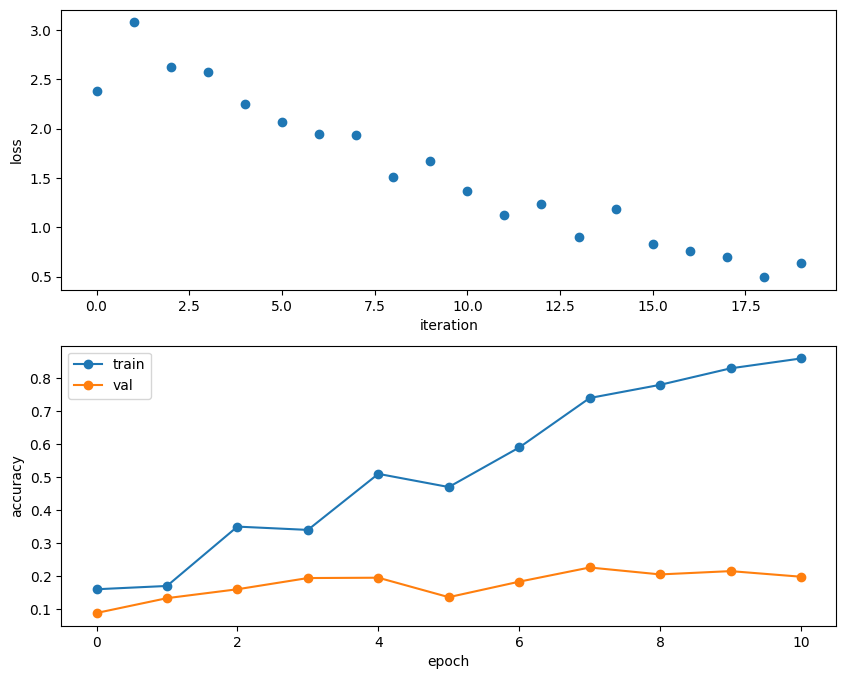

In [7]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, "o")
plt.xlabel("iteration")
plt.ylabel("loss")

plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, "-o")
plt.plot(solver.val_acc_history, "-o")
plt.legend(["train", "val"], loc="upper left")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.show()

## Train the network

Now we train the 3 layer CNN on CIFAR-10 and assess its accuracy.

In [8]:
model = ThreeLayerConvNet(weight_scale=0.001, hidden_dim=500, reg=0.001)

solver = Solver(
    model,
    data,
    num_epochs=1,
    batch_size=50,
    update_rule="adam",
    optim_config={
        "learning_rate": 1e-3,
    },
    verbose=True,
    print_every=20,
)
solver.train()

useing batch
(Iteration 1 / 980) loss: 2.304733
(Epoch 0 / 1) train acc: 0.089000; val_acc: 0.111000
(Iteration 21 / 980) loss: 2.157575
(Iteration 41 / 980) loss: 1.757742
(Iteration 61 / 980) loss: 1.918615
(Iteration 81 / 980) loss: 1.948676
(Iteration 101 / 980) loss: 1.769612
(Iteration 121 / 980) loss: 1.861677
(Iteration 141 / 980) loss: 1.700638
(Iteration 161 / 980) loss: 1.858089
(Iteration 181 / 980) loss: 1.894187
(Iteration 201 / 980) loss: 2.002290
(Iteration 221 / 980) loss: 1.847732
(Iteration 241 / 980) loss: 1.852248
(Iteration 261 / 980) loss: 1.698909
(Iteration 281 / 980) loss: 1.916283
(Iteration 301 / 980) loss: 1.743662
(Iteration 321 / 980) loss: 1.752023
(Iteration 341 / 980) loss: 2.061709
(Iteration 361 / 980) loss: 1.718637
(Iteration 381 / 980) loss: 1.678861
(Iteration 401 / 980) loss: 1.769799
(Iteration 421 / 980) loss: 1.603542
(Iteration 441 / 980) loss: 1.761914
(Iteration 461 / 980) loss: 1.715985
(Iteration 481 / 980) loss: 1.731142
(Iteration 501 

# Get > 65% validation accuracy on CIFAR-10.

In the last part of the assignment, we'll now ask you to train a CNN to get better than 65% validation accuracy on CIFAR-10.

### Things you should try:
- Filter size: Above we used 7x7; but VGGNet and onwards showed stacks of 3x3 filters are good.  
- Number of filters: Above we used 32 filters. Do more or fewer do better?
- Batch normalization: Try adding spatial batch normalization after convolution layers and vanilla batch normalization aafter affine layers. Do your networks train faster?
- Network architecture: Can a deeper CNN do better?  Consider these architectures:
    - [conv-relu-pool]xN - conv - relu - [affine]xM - [softmax or SVM]
    - [conv-relu-pool]XN - [affine]XM - [softmax or SVM]
    - [conv-relu-conv-relu-pool]xN - [affine]xM - [softmax or SVM]

### Tips for training
For each network architecture that you try, you should tune the learning rate and regularization strength. When doing this there are a couple important things to keep in mind:

- If the parameters are working well, you should see improvement within a few hundred iterations
- Remember the coarse-to-fine approach for hyperparameter tuning: start by testing a large range of hyperparameters for just a few training iterations to find the combinations of parameters that are working at all.
- Once you have found some sets of parameters that seem to work, search more finely around these parameters. You may need to train for more epochs.

In [6]:
# ================================================================ #
# YOUR CODE HERE:
#   Implement a CNN to achieve greater than 65% validation accuracy
#   on CIFAR-10.
# ================================================================ #
model = ThreeLayerConvNet(num_filters=64, filter_size=3, weight_scale=0.001, hidden_dim=500, reg=0.001)

solver = Solver(
    model,
    {
        "X_train": data["X_train"],
        "y_train": data["y_train"],
        "X_val": data["X_val"],
        "y_val": data["y_val"],
    },
    num_epochs=5,
    batch_size=50,
    update_rule="adam",
    optim_config={
        "learning_rate": 5e-4,
    },
    verbose=True,
    print_every=100,
)
solver.train()
# ================================================================ #
# END YOUR CODE HERE
# ================================================================ #

useing batch
(Iteration 1 / 4900) loss: 2.306714
(Epoch 0 / 5) train acc: 0.107000; val_acc: 0.103000
(Iteration 101 / 4900) loss: 1.686813
(Iteration 201 / 4900) loss: 1.570076
(Iteration 301 / 4900) loss: 1.510764
(Iteration 401 / 4900) loss: 1.498686
(Iteration 501 / 4900) loss: 1.426701
(Iteration 601 / 4900) loss: 1.309289
(Iteration 701 / 4900) loss: 1.420431
(Iteration 801 / 4900) loss: 1.644663
(Iteration 901 / 4900) loss: 1.426895
(Epoch 1 / 5) train acc: 0.538000; val_acc: 0.531000
(Iteration 1001 / 4900) loss: 1.375730
(Iteration 1101 / 4900) loss: 1.050852
(Iteration 1201 / 4900) loss: 1.043520
(Iteration 1301 / 4900) loss: 1.314496
(Iteration 1401 / 4900) loss: 1.336099
(Iteration 1501 / 4900) loss: 1.151361
(Iteration 1601 / 4900) loss: 1.451277
(Iteration 1701 / 4900) loss: 1.108598
(Iteration 1801 / 4900) loss: 1.197014
(Iteration 1901 / 4900) loss: 1.413920
(Epoch 2 / 5) train acc: 0.633000; val_acc: 0.601000
(Iteration 2001 / 4900) loss: 1.185735
(Iteration 2101 / 490

In [10]:
# ================================================================ #
# YOUR CODE HERE:
#   Implement a CNN to achieve greater than 65% validation accuracy
#   on CIFAR-10.
# ================================================================ #
model = ThreeLayerConvNet(num_filters=64, filter_size=3, weight_scale=0.001, hidden_dim=500, reg=0.001, use_batchnorm=True)

solver = Solver(
    model,
    {
        "X_train": data["X_train"],
        "y_train": data["y_train"],
        "X_val": data["X_val"],
        "y_val": data["y_val"],
    },
    num_epochs=2,
    batch_size=50,
    update_rule="adam",
    optim_config={
        "learning_rate": 5e-4,
    },
    verbose=True,
    print_every=100,
)
solver.train()
# ================================================================ #
# END YOUR CODE HERE
# ================================================================ #

useing batch
(Iteration 1 / 1960) loss: 2.309278
(Epoch 0 / 2) train acc: 0.171000; val_acc: 0.164000
(Iteration 101 / 1960) loss: 1.852503
(Iteration 201 / 1960) loss: 1.380217
(Iteration 301 / 1960) loss: 1.515023
(Iteration 401 / 1960) loss: 1.648367
(Iteration 501 / 1960) loss: 1.358389
(Iteration 601 / 1960) loss: 1.353898
(Iteration 701 / 1960) loss: 1.278916
(Iteration 801 / 1960) loss: 1.694289
(Iteration 901 / 1960) loss: 1.338063
(Epoch 1 / 2) train acc: 0.616000; val_acc: 0.560000
(Iteration 1001 / 1960) loss: 1.174704
(Iteration 1101 / 1960) loss: 1.207546
(Iteration 1201 / 1960) loss: 1.298671
(Iteration 1301 / 1960) loss: 1.453849
(Iteration 1401 / 1960) loss: 1.587605
(Iteration 1501 / 1960) loss: 1.109607
(Iteration 1601 / 1960) loss: 1.227977
(Iteration 1701 / 1960) loss: 1.205376
(Iteration 1801 / 1960) loss: 1.339859
(Iteration 1901 / 1960) loss: 1.113560
(Epoch 2 / 2) train acc: 0.647000; val_acc: 0.607000


In [5]:
# ================================================================ #
# YOUR CODE HERE:
#   Implement a CNN to achieve greater than 65% validation accuracy
#   on CIFAR-10.
# ================================================================ #
model = ThreeLayerConvNet(num_filters=64, filter_size=3, weight_scale=0.001, hidden_dim=500, reg=0.001, use_batchnorm=True)

solver = Solver(
    model,
    {
        "X_train": data["X_train"],
        "y_train": data["y_train"],
        "X_val": data["X_val"],
        "y_val": data["y_val"],
    },
    num_epochs=5,
    batch_size=50,
    update_rule="adam",
    optim_config={
        "learning_rate": 5e-4,
    },
    verbose=True,
    print_every=100,
)
solver.train()
# ================================================================ #
# END YOUR CODE HERE
# ================================================================ #

useing batch
(Iteration 1 / 4900) loss: 2.307712
(Epoch 0 / 5) train acc: 0.120000; val_acc: 0.126000
(Iteration 101 / 4900) loss: 1.498024
(Iteration 201 / 4900) loss: 1.363386
(Iteration 301 / 4900) loss: 1.579727
(Iteration 401 / 4900) loss: 1.562077
(Iteration 501 / 4900) loss: 1.315815
(Iteration 601 / 4900) loss: 1.272525
(Iteration 701 / 4900) loss: 1.635684
(Iteration 801 / 4900) loss: 1.431280
(Iteration 901 / 4900) loss: 1.322684
(Epoch 1 / 5) train acc: 0.586000; val_acc: 0.539000
(Iteration 1001 / 4900) loss: 1.225608
(Iteration 1101 / 4900) loss: 1.445865
(Iteration 1201 / 4900) loss: 1.743167
(Iteration 1301 / 4900) loss: 1.247783
(Iteration 1401 / 4900) loss: 1.713361
(Iteration 1501 / 4900) loss: 1.161369
(Iteration 1601 / 4900) loss: 1.004059
(Iteration 1701 / 4900) loss: 1.227925
(Iteration 1801 / 4900) loss: 1.436284
(Iteration 1901 / 4900) loss: 1.191592
(Epoch 2 / 5) train acc: 0.629000; val_acc: 0.580000
(Iteration 2001 / 4900) loss: 1.097310
(Iteration 2101 / 490

## Question

Describe the final architecture and hyperparameters you used to achieve >65% validation accuracy. What changes had the biggest impact on performance? If you used batch normalization, how did it affect training speed and final accuracy compared to training without it?

## Answer
Increasing the epochs and using batch norm had the biggest impact on performace. I also increased the number of filters and reduce the filter size, and the learning rate a bit smaller but it didn't give me much improvement. Batch norm was a bit slower than not using batch norm. 28min vs 35min